# Município contracts

Contracts whose **adjudicante** name starts with "Município".

**Rule:** after splitting the packed `NIPC - name` field, the name is accent-folded and lowercased
(`normalize_name()`), then matched with `startswith("municipio")`. A naive `starts_with("Município")`
would lose ~3 % of rows (unaccented / uppercase variants such as `MUNICÍPIO DA FIGUEIRA DA FOZ`).

Reference values on the current parquet: **564 493 rows, 302 distinct NIPC** (checked against the data).

Caveats: 302 NIPCs vs 308 real municipalities → the rule misses some municipalities and may
still include false positives (e.g. `Município de Formação AIRC`); not reconciled here. `Câmara Municipal …` names do **not** start with "Município"
and are deliberately excluded (see the near-miss cell).

In [1]:
from pathlib import Path

import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import polars as pl

from base_gov.contracts import is_municipio_expr, load_contracts
from base_gov.entities import (
    canonical_names,
    normalize_name,
)
from base_gov.stats import MIN_VALUE, value_impact

DATA = Path("..") / "data"
pl.Config.set_tbl_rows(20)
pl.Config.set_tbl_width_chars(140)
plt.rcParams["figure.figsize"] = (10, 4)

In [2]:
contracts_all = load_contracts(DATA / "contracts.parquet")
print(f"rows={contracts_all.height:,}  cols={contracts_all.width}")
# Disregard contracts flagged is_below_min_value (|preco_contratual| < MIN_VALUE, €); contracts_all keeps them for before/after comparisons.
contracts = contracts_all.filter(~pl.col("is_below_min_value"))
print(f"disregarded {contracts_all.height - contracts.height:,} contracts with |preco_contratual| < €{MIN_VALUE:g} "
      f"({(contracts_all.height - contracts.height) / contracts_all.height:.2%}); kept {contracts.height:,}")
print(f"valor_por_dia defined for {contracts['valor_por_dia'].is_not_null().mean():.1%} of kept contracts "
      f"(needs 1 <= prazo_execucao <= 3650 days)")
contracts.head()

rows=2,295,074  cols=30
disregarded 12,658 contracts with |preco_contratual| < €10 (0.55%); kept 2,282,416
valor_por_dia defined for 97.9% of kept contracts (needs 1 <= prazo_execucao <= 3650 days)


idcontrato,ano,adjudicante,adjudicante_nipc,adjudicante_name,adjudicante_key,adjudicante_key_source,adjudicatarios,objecto_contrato,desc_contrato,preco_contratual,preco_total_efetivo,preco_base_procedimento,prazo_execucao,valor_por_dia,data_celebracao,data_publicacao,data_fecho,tipo_contrato,tipo_procedimento,fundament_ajuste_direto,cpv,nuts,concorrentes,n_concorrentes,is_municipio,is_below_min_value,row_hash,first_ingested_at,updated_at
i64,i32,str,str,str,str,str,str,str,str,f64,f64,f64,i64,f64,date,date,date,str,str,str,str,str,str,u32,bool,bool,i64,"datetime[μs, UTC]","datetime[μs, UTC]"
11837094,2025,"""510103448 - Unidade Local de S…","""510103448""","""Unidade Local de Saúde de Coim…","""510103448""","""nipc""","""502248793 - MYLAN, LDA""","""EVEROLÍMUS 10 MG COMP""","""EVEROLÍMUS 10 MG COMP""",5469.24,0.0,5469.24,20,273.462,2025-09-08,2025-10-24,null,"""Aquisição de bens móveis""","""Ajuste Direto Regime Geral""",null,"""cpvID=33600000-6|cpvdescricao=…","""PT16E - Região de Coimbra""",null,null,false,false,-8325278450096791371,2026-11-16 21:42:47.218292 UTC,2026-11-16 21:42:47.218292 UTC
11941300,2025,"""510103448 - Unidade Local de S…","""510103448""","""Unidade Local de Saúde de Coim…","""510103448""","""nipc""","""508107997 - GENERIS""","""PREGABALINA 50 MG CÁPS""","""PREGABALINA 50 MG CÁPS""",176.4,0.0,224.28,20,8.82,2025-10-03,2025-11-12,null,"""Aquisição de bens móveis""","""Ajuste Direto Regime Geral""",null,"""cpvID=33600000-6|cpvdescricao=…","""PT16E - Região de Coimbra""",null,null,false,false,5147521430359512469,2026-11-16 21:42:47.218292 UTC,2026-11-16 21:42:47.218292 UTC
11593798,2025,"""510103448 - Unidade Local de S…","""510103448""","""Unidade Local de Saúde de Coim…","""510103448""","""nipc""","""- - BRIDGE TO LIFE EUROPE, LTO""","""0402-3091-2025 (Kits Perfusão …","""0402-3091-2025 (Kits Perfusão …",111000.0,111000.0,111000.0,20,5550.0,2025-07-09,2025-07-21,2025-07-21,"""Aquisição de bens móveis""","""Ajuste Direto Regime Geral""",null,"""cpvID=33000000-0|cpvdescricao=…","""PT16E - Região de Coimbra""",null,null,false,false,617016025134681594,2026-11-16 21:42:47.218292 UTC,2026-11-16 21:42:47.218292 UTC
11898049,2025,"""508481287 - Unidade Local de S…","""508481287""","""Unidade Local de Saúde de Sant…","""508481287""","""nipc""","""502120070 - KONICA MINOLTA BUS…","""Concurso Público com publicida…","""Concurso Público com publicida…",395100.0,0.0,395280.0,1096,360.492701,2025-10-31,2025-11-04,null,"""Aquisição de serviços""","""Concurso público""",null,"""cpvID=50310000-1|cpvdescricao=…","""PT170 - Área Metropolitana de …","""502120070-KONICA MINOLTA BUSIN…",1,false,false,8067913044914378299,2026-11-16 21:42:47.218292 UTC,2026-11-16 21:42:47.218292 UTC
11968011,2025,"""506632920 - Município da Póvoa…","""506632920""","""Município da Póvoa de Lanhoso""","""506632920""","""nipc""","""- - Vanessa Fernanda Sá Pereir…",""" PRESTAÇÃO DE SERVIÇOS EM REGI…",""" PRESTAÇÃO DE SERVIÇOS EM REGI…",17400.0,0.0,17400.0,365,47.671233,2025-11-07,2025-11-20,null,"""Aquisição de serviços""","""Ajuste Direto Regime Geral""",null,"""cpvID=90000000-7|cpvdescricao=…","""PT119 - Ave""",null,null,true,false,1768699952337931715,2026-11-16 21:42:47.218292 UTC,2026-11-16 21:42:47.218292 UTC


In [3]:
municipio = contracts.filter(is_municipio_expr())
n_entities = municipio["adjudicante_key"].n_unique()
print(f"Município rows: {municipio.height:,}  distinct keys: {n_entities}  "
      f"share of all contracts: {municipio.height / contracts.height:.1%}")
assert 0 < municipio.height < contracts.height

Município rows: 564,493  distinct keys: 302  share of all contracts: 24.7%


In [4]:
# Effect of disregarding contracts with |value| below €10 on Município contracts.
before = contracts_all.filter(is_municipio_expr())
display(value_impact(before, municipio))

metric,before,after,change,change_pct
str,f64,f64,f64,f64
"""n_contracts""",565806.0,564493.0,-1313.0,-0.23
"""mean_value""",70485.212927,70649.156603,163.943676,0.23
"""median_value""",16760.0,16800.0,40.0,0.24
"""total_value""",3.9881e10,3.9881e10,-2026.840004,-0.0


prazo_execucao outside 1..3650 days (excluded from value/day): 14,501 of 564,493


prazo_p10,prazo_p25,prazo_p50,prazo_p75,prazo_p90,eur_dia_p10,eur_dia_p25,eur_dia_p50,eur_dia_p75,eur_dia_p90
f64,f64,f64,f64,f64,f64,f64,f64,f64,f64
5.0,30.0,90.0,365.0,700.0,23.33,52.05,247.33,916.67,2725.0


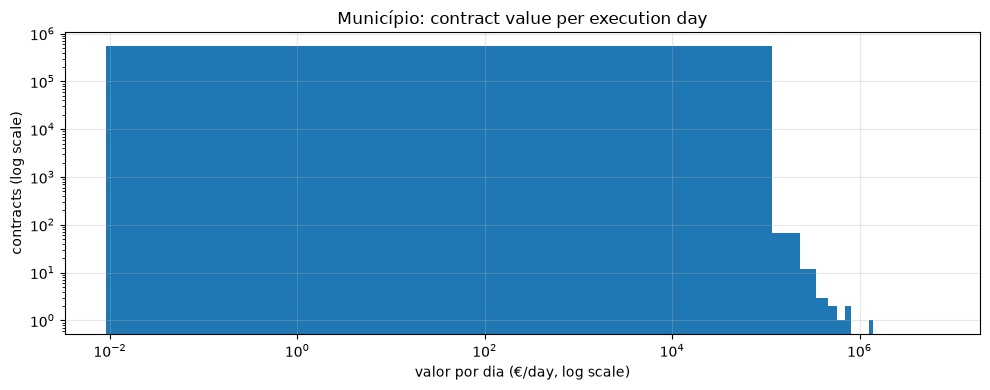

In [5]:
# Execution time (prazo_execucao, days) and value per day. valor_por_dia is null outside 1..3650 days.
d = municipio
print(f"prazo_execucao outside 1..3650 days (excluded from value/day): {d['valor_por_dia'].is_null().sum():,} of {d.height:,}")
display(d.select(
    *[pl.col("prazo_execucao").quantile(q).alias(f"prazo_p{int(q * 100)}") for q in (0.1, 0.25, 0.5, 0.75, 0.9)],
    *[pl.col("valor_por_dia").quantile(q).round(2).alias(f"eur_dia_p{int(q * 100)}") for q in (0.1, 0.25, 0.5, 0.75, 0.9)],
))
vd = d["valor_por_dia"].drop_nulls()
fig, ax = plt.subplots()
ax.hist(vd.filter(vd > 0).to_numpy(), bins=60, log=True)
ax.set_xscale("log")
ax.set_xlabel("valor por dia (€/day, log scale)")
ax.set_ylabel("contracts (log scale)")
ax.set_title("Município: contract value per execution day")
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [6]:
# By duration bucket: how price and price/day move with the contract length.
buckets = (
    municipio.filter(pl.col("valor_por_dia").is_not_null())
    .with_columns(
        pl.when(pl.col("prazo_execucao") <= 30).then(pl.lit("1-30 d"))
        .when(pl.col("prazo_execucao") <= 90).then(pl.lit("31-90 d"))
        .when(pl.col("prazo_execucao") <= 365).then(pl.lit("91-365 d"))
        .otherwise(pl.lit("366-3650 d")).alias("duracao")
    )
    .group_by("duracao")
    .agg(
        pl.len().alias("n_contracts"),
        pl.col("preco_contratual").median().alias("median_value"),
        pl.col("valor_por_dia").median().round(2).alias("median_eur_per_day"),
        pl.col("preco_contratual").sum().round(0).alias("total_value"),
    )
    .sort("median_value")
)
buckets

duracao,n_contracts,median_value,median_eur_per_day,total_value
str,u32,f64,f64,f64
"""1-30 d""",181025,11550.0,936.74,3.7040e9
"""91-365 d""",198075,17975.04,65.86,1.5726e10
"""31-90 d""",91992,23898.63,402.67,4.3921e9
"""366-3650 d""",78900,30000.0,40.05,1.5281e10


In [7]:
print("adjudicante cells with several entries ('\\n'):", municipio.filter(pl.col("adjudicante").str.contains("\n", literal=True)).height,
      "(whole dataset:", contracts.filter(pl.col("adjudicante").str.contains("\n", literal=True)).height, ")")
print("non-9-digit NIPC:", municipio.filter(pl.col("adjudicante_key_source") != "nipc").height)
print("null preco_contratual:", municipio["preco_contratual"].null_count())
print("null data_celebracao:", municipio["data_celebracao"].null_count())
print("no-NIF ('-') adjudicante rows, whole dataset:", contracts.filter(pl.col("adjudicante_key_source") == "name").height)
print(contracts["adjudicante_key_source"].value_counts(sort=True))


adjudicante cells with several entries ('\n'): 29 (whole dataset: 1105 )
non-9-digit NIPC: 0
null preco_contratual: 0
null data_celebracao: 12367
no-NIF ('-') adjudicante rows, whole dataset: 26
shape: (2, 2)
┌────────────────────────┬─────────┐
│ adjudicante_key_source ┆ count   │
│ ---                    ┆ ---     │
│ str                    ┆ u32     │
╞════════════════════════╪═════════╡
│ nipc                   ┆ 2282390 │
│ name                   ┆ 26      │
└────────────────────────┴─────────┘


In [8]:
# Names containing "munic" that the rule does NOT match (justifies the prefix rule).
near_miss = (
    contracts
    .with_columns(pl.col("adjudicante_name").map_elements(normalize_name, return_dtype=pl.String).alias("norm_name"))
    .filter(pl.col("norm_name").str.contains("munic") & ~pl.col("norm_name").str.starts_with("municipio"))
    .group_by("adjudicante_key")
    .agg(pl.len().alias("n_contracts"))
    .join(canonical_names(contracts, prefix="adjudicante"), on="adjudicante_key", how="left")
    .sort("n_contracts", descending=True)
)
print(f"excluded near-miss rows: {near_miss['n_contracts'].sum():,}")
near_miss.head(15)


excluded near-miss rows: 85,735


adjudicante_key,n_contracts,adjudicante_name
str,u32,str
"""505037700""",8003,"""CMPH - DomusSocial - Empresa d…"
"""501305912""",6171,"""Câmara Municipal de Matosinhos"""
"""503541567""",3798,"""Gebalis - Gestão do Arrendamen…"
"""680009671""",3229,"""Serviços Intermunicipalizados …"
"""502017368""",2869,"""Autoridade Nacional de Comunic…"
"""501091823""",2805,"""Câmara Municipal de Felgueiras"""
"""507718666""",2687,"""CMPEAE - Empresa de Águas e En…"
"""680000054""",2553,"""Serviços Municipalizados de Si…"
"""501394192""",2072,"""Associação de Municípios para …"


In [9]:
by_entity = (
    municipio
    .group_by("adjudicante_key")
    .agg(
        pl.len().alias("n_contracts"),
        pl.col("preco_contratual").sum().round(2).alias("total_value"),
    )
    .join(canonical_names(municipio, prefix="adjudicante"), on="adjudicante_key", how="left")
)
assert by_entity["n_contracts"].sum() == municipio.height

print("Top 20 municipalities by contract count:")
display(by_entity.sort("n_contracts", descending=True).head(20))
print("\nTop 20 municipalities by total contracted value:")
display(by_entity.sort("total_value", descending=True).head(20))


Top 20 municipalities by contract count:


adjudicante_key,n_contracts,total_value,adjudicante_name
str,u32,f64,str
"""500051070""",18253,2.1781e9,"""Município de Lisboa"""
"""500745943""",9364,1.0532e9,"""Município de Oeiras"""
"""500051062""",8857,9.1081e8,"""Município de Sintra"""
"""502098139""",8000,6.0520e8,"""Município de Loulé"""
"""506663264""",6939,5.5746e8,"""MUNICÍPIO DE VILA NOVA DE FAMA…"
"""501306099""",6851,5.6989e8,"""Municipio do Porto"""
"""501294104""",6331,4.2485e8,"""Município de Setúbal"""
"""505187531""",5605,1.2257e9,"""Município de Cascais"""
"""500051054""",5429,4.1720e8,"""Município de Almada"""



Top 20 municipalities by total contracted value:


adjudicante_key,n_contracts,total_value,adjudicante_name
str,u32,f64,str
"""500051070""",18253,2.1781e9,"""Município de Lisboa"""
"""505187531""",5605,1.2257e9,"""Município de Cascais"""
"""500745943""",9364,1.0532e9,"""Município de Oeiras"""
"""500051062""",8857,9.1081e8,"""Município de Sintra"""
"""501294996""",5379,6.1932e8,"""Município de Loures"""
"""505335018""",4614,6.1223e8,"""Município de Vila Nova de Gaia"""
"""502098139""",8000,6.0520e8,"""Município de Loulé"""
"""501306099""",6851,5.6989e8,"""Municipio do Porto"""
"""506663264""",6939,5.5746e8,"""MUNICÍPIO DE VILA NOVA DE FAMA…"


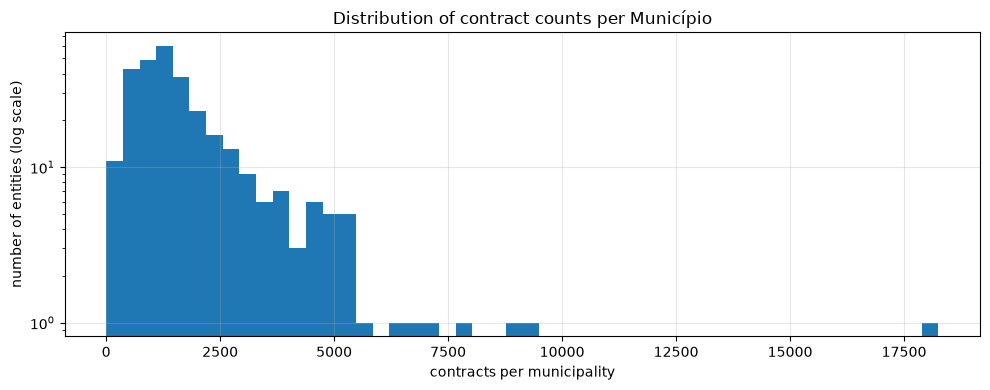

shape: (9, 2)
┌────────────┬─────────────┐
│ statistic  ┆ value       │
│ ---        ┆ ---         │
│ str        ┆ f64         │
╞════════════╪═════════════╡
│ count      ┆ 302.0       │
│ null_count ┆ 0.0         │
│ mean       ┆ 1869.182119 │
│ std        ┆ 1734.896319 │
│ min        ┆ 1.0         │
│ 25%        ┆ 852.0       │
│ 50%        ┆ 1394.0      │
│ 75%        ┆ 2224.0      │
│ max        ┆ 18253.0     │
└────────────┴─────────────┘


In [10]:
fig, ax = plt.subplots()
ax.hist(by_entity["n_contracts"].to_numpy(), bins=50, log=True)
ax.set_xlabel("contracts per municipality")
ax.set_ylabel("number of entities (log scale)")
ax.set_title("Distribution of contract counts per Município")
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()
print(by_entity["n_contracts"].describe())


In [11]:
total_value = municipio["preco_contratual"].sum()
print(f"total value: €{total_value / 1e6:,.1f}M  median contract: €{municipio['preco_contratual'].median():,.0f}")
(
    municipio.group_by("tipo_procedimento")
    .agg(pl.len().alias("n_contracts"), pl.col("preco_contratual").sum().round(2).alias("total_value"))
    .with_columns(
        (pl.col("n_contracts") / pl.col("n_contracts").sum() * 100).round(1).alias("pct_count"),
        (pl.col("total_value") / pl.col("total_value").sum() * 100).round(1).alias("pct_value"),
    )
    .sort("n_contracts", descending=True)
)


total value: €39,881.0M  median contract: €16,800


tipo_procedimento,n_contracts,total_value,pct_count,pct_value
str,u32,f64,f64,f64
"""Ajuste Direto Regime Geral""",340916,8.1737e9,60.4,20.5
"""Consulta Prévia""",124109,4.8877e9,22.0,12.3
"""Concurso público""",74850,2.2631e10,13.3,56.7
"""Ajuste direto simplificado""",12211,3.0382e7,2.2,0.1
"""Ao abrigo de acordo-quadro (ar…",4636,1.7365e9,0.8,4.4
"""Ao abrigo de acordo-quadro (ar…",4070,1.0131e9,0.7,2.5
"""Contratação excluída II""",2398,4.1464e8,0.4,1.0
"""Consulta Prévia Simplificada""",665,1.0311e8,0.1,0.3
"""Concurso limitado por prévia q…",445,7.5864e8,0.1,1.9


In [12]:
print("tipo_contrato:")
display(municipio["tipo_contrato"].value_counts(sort=True).head(15))
print("\nTop 15 CPV:")
display(municipio["cpv"].value_counts(sort=True).head(15))


tipo_contrato:


tipo_contrato,count
str,u32
"""Aquisição de serviços""",309286
"""Aquisição de bens móveis""",146527
"""Empreitadas de obras públicas""",92522
"""Locação de bens móveis""",9132
"""Aquisição de bens móveis Aquis…",4061
"""Aquisição de serviços Locação …",888
"""Concessão de serviços públicos""",494
"""Outros""",317
"""Concessão de obras públicas""",276



Top 15 CPV:


cpv,count
str,u32
"""cpvID=98390000-3|cpvdescricao=…",398
"""cpvID=92620000-3|cpvdescricao=…",293
"""cpvID=45000000-7|cpvdescricao=…",292
"""cpvID=45233200-1|cpvdescricao=…",242
"""cpvID=60130000-8|cpvdescricao=…",226
"""cpvID=98300000-6|cpvdescricao=…",226
"""cpvID=92000000-1|cpvdescricao=…",204
"""cpvID=92000000-1|cpvdescricao=…",194
"""cpvID=98300000-6|cpvdescricao=…",181


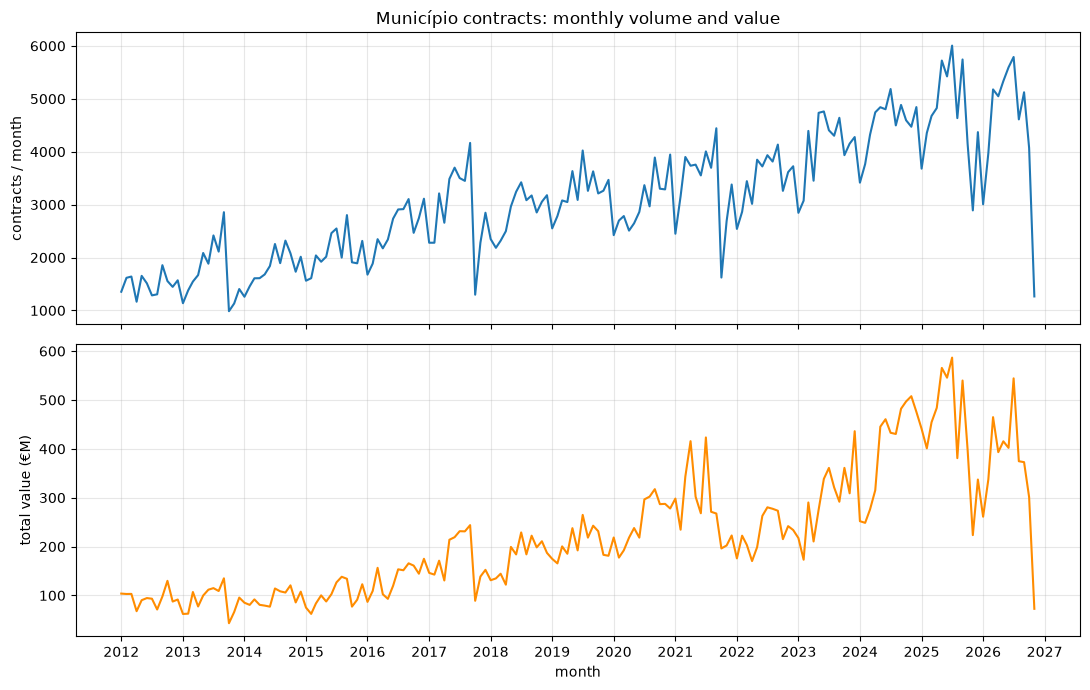

In [13]:
monthly = (
    municipio.filter(pl.col("data_celebracao").is_not_null())
    .with_columns(pl.col("data_celebracao").dt.truncate("1mo").alias("month"))
    .group_by("month")
    .agg(pl.len().alias("n_contracts"), pl.col("preco_contratual").sum().alias("total_value"))
    .sort("month")
)
fig, axes = plt.subplots(2, 1, figsize=(11, 7), sharex=True)
axes[0].plot(monthly["month"], monthly["n_contracts"])
axes[0].set_ylabel("contracts / month")
axes[0].set_title("Município contracts: monthly volume and value")
axes[1].plot(monthly["month"], monthly["total_value"] / 1e6, color="darkorange")
axes[1].set_ylabel("total value (€M)")
axes[1].set_xlabel("month")
for ax in axes:
    ax.xaxis.set_major_locator(mdates.YearLocator())
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
    ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()


In [14]:
municipio.sort("preco_contratual", descending=True, nulls_last=True).select(
    "idcontrato", "adjudicante_name", "preco_contratual", "tipo_procedimento", "data_celebracao", "objecto_contrato"
).head(10)


idcontrato,adjudicante_name,preco_contratual,tipo_procedimento,data_celebracao,objecto_contrato
i64,str,f64,str,date,str
7632662,"""Município de Lisboa""",1.329e8,"""Concurso público""",2021-04-28,"""EMPREITADA Nº 18/CPI/EPPGDL/18…"
10738425,"""Município de Cascais""",1.3180e8,"""Concurso público""",2024-05-15,"""Aquisição de serviços de trans…"
13482357,"""Município de Cascais""",5e7,"""Contratação excluída II""",2026-02-18,"""Promoção da construção, manute…"
10320226,"""MUNICÍPIO DE VILA NOVA DE FAMA…",4.8552e7,"""Concurso público""",2023-10-18,"""Serviço público de transporte …"
11470653,"""Município de Cascais""",4.7170e7,"""Contratação excluída II""",2022-02-04,"""Contrato para a promoção da co…"
6904752,"""Município de Oeiras""",4.4989e7,"""Concurso público""",2020-08-28,"""2019/94 - DEM - Construção do …"
7773889,"""Município de Sintra""",4.4933e7,"""Concurso público""",2021-07-20,"""Empreitada de Construção do Ho…"
13255178,"""Municipio de Vila Real de Sant…",4.4563e7,"""Concurso público""",2025-01-10,"""Empreitada de Reabilitação do …"
9402417,"""MUNICÍPIO DE ALBUFEIRA""",4.0001e7,"""Concurso público""",2022-06-30,"""Concurso público com publicaçã…"


## Commentary and limitations

- The matching rule may include false positives (302 NIPCs vs 308 municipalities) and excludes `Câmara Municipal …`.
- `Ano` covers 2012–2026 (data up to 2026-11-14); edge months of the monthly series are partial.
- Top-value contracts should be checked as possible outliers or data-entry errors.- Municipalities are keyed by NIPC (`adjudicante_key`); a `-` NIPC would fall back to name similarity.

- Contracts with |value| below €10 are disregarded; `valor_por_dia` uses only 1–3650-day durations.